# Part B: Exploratory Data Analysis


## 1. Setup & Data Ingestion


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

df = pd.read_csv('default of credit card clients.csv')
print(f"Dataset loaded: {df.shape[0]:,} observations, {df.shape[1]} attributes.")

ImportError: Unable to import required dependencies:
numpy: cannot import name 'set_module' from 'numpy._utils' (unknown location)

## 2. Descriptive Statistics


In [ ]:
# Numerical summary
numeric_cols = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3']
desc_stats = df[numeric_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats.round(2)

,mean,std,min,25%,50%,75%,max,IQR
LIMIT_BAL,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,190000.00
AGE,35.49,9.22,21.0,28.00,34.0,41.00,79.0,13.00
BILL_AMT1,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.00,964511.0,63532.25
BILL_AMT2,49179.08,71173.77,-69777.0,2984.75,21200.0,64006.25,983931.0,61021.50
BILL_AMT3,47013.15,69349.39,-157264.0,2666.25,20088.5,60164.75,1664089.0,57498.50
PAY_AMT1,5663.58,16563.28,0.0,1000.00,2100.0,5006.00,873552.0,4006.00
PAY_AMT2,5921.16,23040.87,0.0,833.00,2009.0,5000.00,1684259.0,4167.00
PAY_AMT3,5225.68,17606.96,0.0,390.00,1800.0,4505.00,896040.0,4115.00


## 3. Correlation Analysis & Multicollinearity


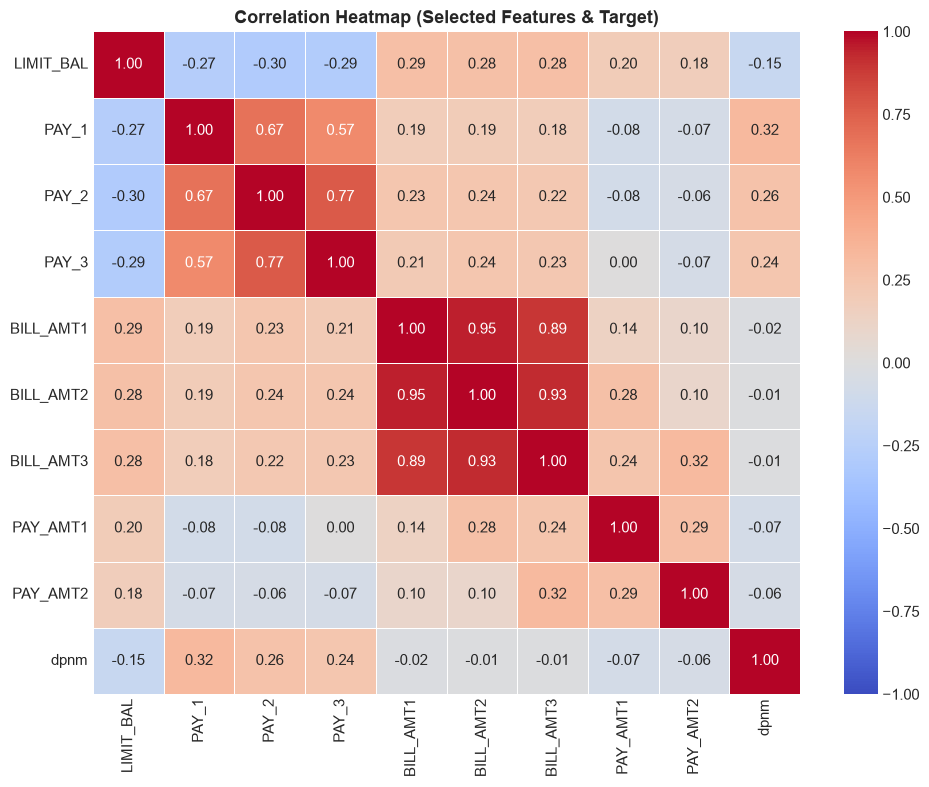

Key Finding: Extreme collinearity between consecutive billing statements (BILL_AMT1 & BILL_AMT2: r = 0.95).
PAY_1 (most recent repayment status) has the strongest single linear correlation with default (r = 0.32).


In [ ]:
# Correlation heatmap among billing and repayment amounts
corr_cols = ['LIMIT_BAL', 'PAY_1', 'PAY_2', 'PAY_3', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'PAY_AMT1', 'PAY_AMT2', 'dpnm']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap (Selected Features & Target)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Key Finding: Extreme collinearity between consecutive billing statements (BILL_AMT1 & BILL_AMT2: r = 0.95).")
print("PAY_1 (most recent repayment status) has the strongest single linear correlation with default (r = 0.32).")

## 4. Feature Distributions & Skewness Analysis


Top 10 Most Positively Skewed Features:
           Skewness
PAY_AMT2     30.454
PAY_AMT3     17.217
PAY_AMT1     14.668
PAY_AMT4     12.905
PAY_AMT5     11.127
PAY_AMT6     10.641
BILL_AMT3     3.088
BILL_AMT5     2.876
BILL_AMT6     2.847
BILL_AMT4     2.822


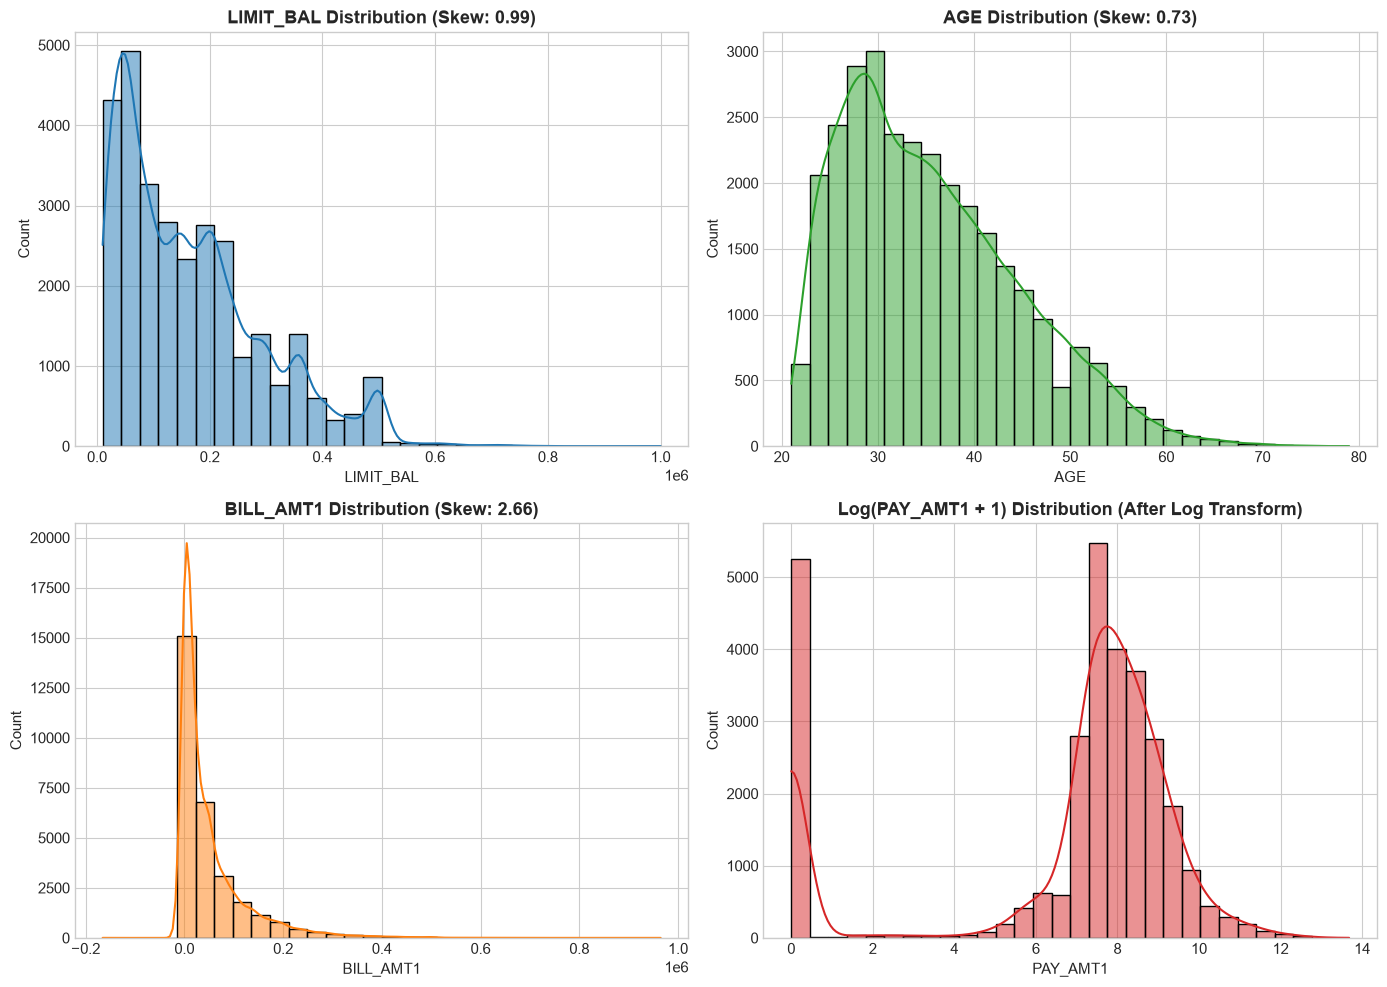

In [ ]:
# Calculate skewness for all numerical features
skew_values = df.skew().sort_values(ascending=False)
skew_df = pd.DataFrame({'Skewness': skew_values.round(3)})
print("Top 10 Most Positively Skewed Features:")
print(skew_df.head(10))

# Visualise distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['LIMIT_BAL'], kde=True, color='#1f77b4', ax=axes[0, 0], bins=30)
axes[0, 0].set_title(f"LIMIT_BAL Distribution (Skew: {df['LIMIT_BAL'].skew():.2f})", fontweight='bold')

sns.histplot(df['AGE'], kde=True, color='#2ca02c', ax=axes[0, 1], bins=30)
axes[0, 1].set_title(f"AGE Distribution (Skew: {df['AGE'].skew():.2f})", fontweight='bold')

sns.histplot(df['BILL_AMT1'], kde=True, color='#ff7f0e', ax=axes[1, 0], bins=30)
axes[1, 0].set_title(f"BILL_AMT1 Distribution (Skew: {df['BILL_AMT1'].skew():.2f})", fontweight='bold')

sns.histplot(np.log1p(df['PAY_AMT1'].clip(lower=0)), kde=True, color='#d62728', ax=axes[1, 1], bins=30)
axes[1, 1].set_title(f"Log(PAY_AMT1 + 1) Distribution (After Log Transform)", fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Missing Values & Duplicate Records Analysis


In [ ]:
# Missing values
missing = df.isnull().sum()
print(f"Total explicit null/missing values: {missing.sum()}")

# Duplicate records excluding arbitrary ID
feature_cols = [c for c in df.columns if c != 'ID']
dup_count = df.duplicated(subset=feature_cols).sum()
print(f"Exact duplicate client entries found: {dup_count} (35 duplicate pairs, 70 total rows)")

# Inspect sample duplicates
dup_rows = df[df.duplicated(subset=feature_cols, keep=False)].sort_values(by=feature_cols)
print("Sample Duplicate Pair (IDs 19 and 13107):")
dup_rows[dup_rows['ID'].isin([19, 13107])][['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'BILL_AMT1', 'dpnm']]

Total explicit null/missing values: 0
Exact duplicate client entries found: 35 (35 duplicate pairs, 70 total rows)
Sample Duplicate Pair (IDs 19 and 13107):


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,BILL_AMT1,dpnm
18,19,360000,2,1,1,49,0,0
13106,13107,360000,2,1,1,49,0,0


## 6. Outlier Analysis


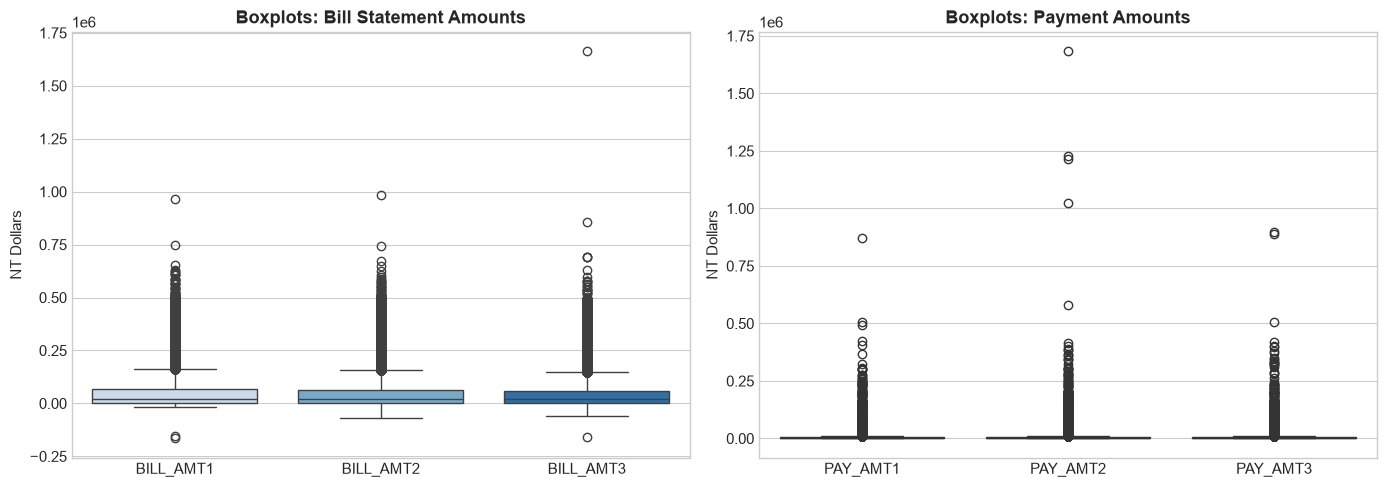

Outlier Insight: Extreme payments and bills exist (up to NT$1M+). These represent legitimate high-net-worth accounts, not errors. Robust scaling is required rather than row deletion.


In [ ]:
# Outlier detection using IQR on billing and payment features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3']], palette='Blues', ax=axes[0])
axes[0].set_title('Boxplots: Bill Statement Amounts', fontweight='bold')
axes[0].set_ylabel('NT Dollars')

sns.boxplot(data=df[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3']], palette='Greens', ax=axes[1])
axes[1].set_title('Boxplots: Payment Amounts', fontweight='bold')
axes[1].set_ylabel('NT Dollars')

plt.tight_layout()
plt.show()

print("Outlier Insight: Extreme payments and bills exist (up to NT$1M+). These represent legitimate high-net-worth accounts, not errors. Robust scaling is required rather than row deletion.")

## 7. Noise & Categorical Inconsistencies


In [ ]:
print("=== CATEGORICAL VALUE COUNTS ===")
print("EDUCATION codes:", df['EDUCATION'].value_counts().to_dict())
print("MARRIAGE codes:", df['MARRIAGE'].value_counts().to_dict())

print("\nInconsistency Identified:")
print("- EDUCATION contains undocumented values: 0 (14 rows), 5 (280 rows), 6 (51 rows).")
print("- MARRIAGE contains undocumented value: 0 (54 rows).")
print("- Solution: Consolidate undocumented EDUCATION codes into 4 ('Others'), and MARRIAGE 0 into 3 ('Others').")

=== CATEGORICAL VALUE COUNTS ===
EDUCATION codes: {2: 14030, 1: 10585, 3: 4917, 5: 280, 4: 123, 6: 51, 0: 14}
MARRIAGE codes: {2: 15964, 1: 13659, 3: 323, 0: 54}

Inconsistency Identified:
- EDUCATION contains undocumented values: 0 (14 rows), 5 (280 rows), 6 (51 rows).
- MARRIAGE contains undocumented value: 0 (54 rows).
- Solution: Consolidate undocumented EDUCATION codes into 4 ('Others'), and MARRIAGE 0 into 3 ('Others').


## 8. Impact of Data Quality Issues on Machine Learning Models
